# The sample data

Every chapter uses one of four small, seeded datasets. They live in `ml8/data.py`,
so the notebooks and the companion dashboard always show exactly the same points.

| Dataset | Used by | Shape |
|---|---|---|
| Regression line | Linear regression | 60 points, $y = 1.8x + 3 + \varepsilon$, $\varepsilon \sim \mathcal N(0, 2.5^2)$ |
| Logistic 1-D | Logistic regression | 60 points, $P(y=1\mid x) = \sigma(1.6(x-5))$ |
| Two moons | Tree, forest, boosting, KNN, neural net | 400 points, noise 0.3, 70/30 stratified train/test split |
| Blobs | k-means | 150 points in three Gaussian clusters |

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ml8 import data, models, scratch, plotting as P
P.use_style()
pd.set_option("display.precision", 4)

In [2]:
reg, lg, moons, blobs = data.regression_data(), data.logistic_data(), data.moons_data(), data.blobs_data()
pd.DataFrame({
    "rows": [len(reg), len(lg), len(moons), len(blobs)],
    "columns": [", ".join(d.columns) for d in (reg, lg, moons, blobs)],
}, index=["regression", "logistic", "moons", "blobs"])

,rows,columns
regression,60,"id, x, y"
logistic,60,"id, x, y"
moons,400,"id, x1, x2, label, split"
blobs,150,"id, x1, x2, true_cluster"


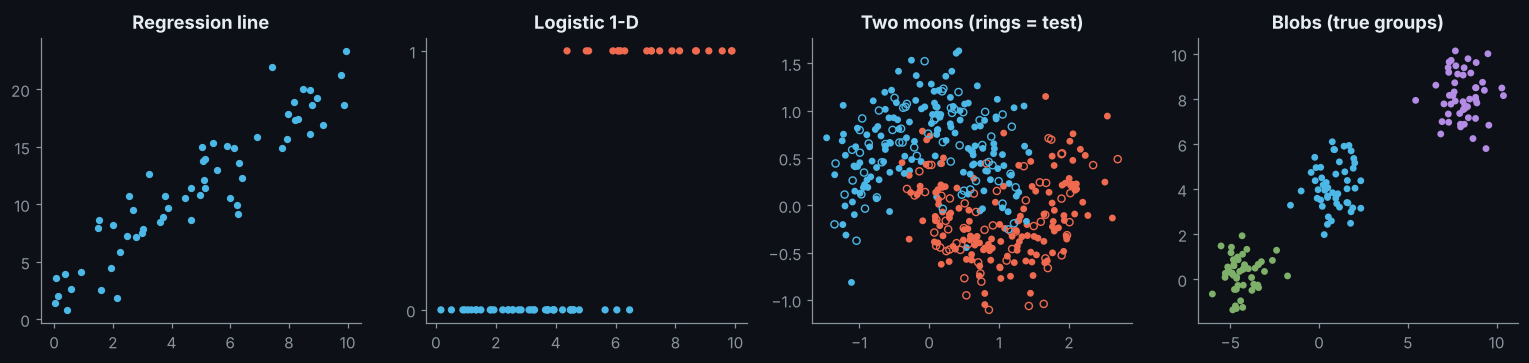

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
ax[0].scatter(reg.x, reg.y, s=14, c=P.BLUE); ax[0].set_title("Regression line")
ax[1].scatter(lg.x, lg.y, s=14, c=P.point_colors(lg.y)); ax[1].set_title("Logistic 1-D"); ax[1].set_yticks([0, 1])
tr = moons[moons.split == "train"]; te = moons[moons.split == "test"]
ax[2].scatter(tr.x1, tr.x2, s=12, c=P.point_colors(tr.label))
ax[2].scatter(te.x1, te.x2, s=22, facecolors="none", edgecolors=P.point_colors(te.label), linewidths=0.9)
ax[2].set_title("Two moons (rings = test)")
ax[3].scatter(blobs.x1, blobs.x2, s=12, c=np.array([P.BLUE, P.GREEN, P.PURPLE])[blobs.true_cluster]); ax[3].set_title("Blobs (true groups)")
plt.tight_layout()

The two-moons set is the workhorse: its classes curl into each other, so a straight
boundary cannot separate them. That makes the differences between the algorithms
easy to see.

In [4]:
moons.groupby(["split", "label"]).size().unstack()

label,0,1
split,,
test,60,60
train,140,140
